# E2: how much CDR the modeled pH can carry

This notebook asks, if we take modeled pH and soil CO2 as correct, how much CDR is available.

There are two ways we close the carbonate system on saved output:

| | hold | solve for |
|---|---|---|
| **E1** (notebook 01) | pCO2, alkalinity | pH | 
| **E2** (here) | pCO2, pH | alkalinity | 


In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, matplotlib.pyplot as plt, matplotlib as mpl
from scipy.optimize import brentq
from beerling_analysis import io, mixing, experiments as X, carbonate as carb

mpl.rcParams.update({"font.size": 10, "figure.dpi": 120, "axes.grid": False})
OI = dict(blue="#0072B2", vermillion="#D55E00", green="#009E73",
          orange="#E69F00", purple="#CC79A7", sky="#56B4E9", grey="0.45")

SITES = io.SITES
RUNS = {(d, c): X.Run(io.load_run(d, c)) for d in SITES for c in (1, 2)}
E2   = {k: X.e2(r) for k, r in RUNS.items()}
E1   = {k: X.e1(r) for k, r in RUNS.items()}

# flux-weighted mean (the export cap is a q-weighted integral)
def fw(r, v):
    return float(np.sum(np.asarray(v) * r.q) / np.sum(r.q))

BASE = X.BASE          # base node, z = 0.15 m
print(f"{len(RUNS)} runs loaded, E1 and E2 computed for each")

12 runs loaded, E1 and E2 computed for each


---
# 1. The bound

At fixed pH and soil pCO₂, carbonate alkalinity is fixed:

$$\mathrm{Alk}(\mathrm{pH},\,p\mathrm{CO_2}) =
K_h \rho\, p\mathrm{CO_2}\frac{\alpha_1 + 2\alpha_2}{\alpha_0}
+ \frac{K_w}{[\mathrm{H^+}]} - [\mathrm{H^+}]
$$

and the change in alkalinity is: 

$$\Delta\mathrm{Alk} = \mathrm{Alk}(\mathrm{pH_{model}},\,p\mathrm{CO_2})
- \mathrm{Alk}(\mathrm{pH_{ctrl}},\,p\mathrm{CO_2})$$

where $\mathrm{pH_{ctrl}}$ is the same soil without feedstock, recovered by subtracting
$2\mathrm{Ca}+2\mathrm{Mg}+\mathrm{K}+\mathrm{Na}$ from the model's linear alkalinity budget. Only added
alkalinity earns CDR. Multiplied by water flux $q$, this is a ceiling on export that holds however much rock dissolves.

We apply it at the base node (z = 0.15 m), where `fd15.m:495` accumulates outflow. Since modeled pH rises
with depth, this is also the most conservative (high CDR) choice.

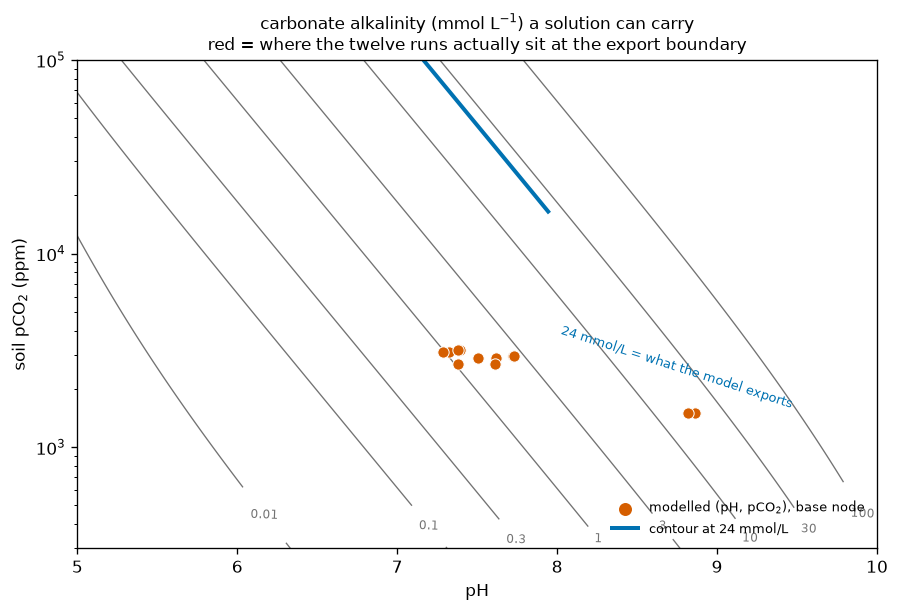

Flux-weighted medians over the twelve runs, at the export boundary (z = 0.15 m):
  modelled pH                    :     7.56
  modelled soil pCO2             :     2918 ppm
  added alkalinity carried       :    23673 ueq/L
  added alkalinity permitted     :     3690 ueq/L
  overcharge                     :      6.4x


In [2]:
# (pH, pCO2) plane with the model's operating points
ph_g  = np.linspace(5.0, 10.0, 400)
co2_g = np.logspace(np.log10(3e2), np.log10(1e5), 400)
PH, CO = np.meshgrid(ph_g, co2_g)
ALK = carb.carbonate_alk(PH, CO) * 1e3      # mmol/L

fig, ax = plt.subplots(figsize=(7.6, 5.2))
lev = np.array([0.01, 0.1, 0.3, 1, 3, 10, 30, 100])
cs = ax.contour(PH, CO, ALK, levels=lev, colors=OI["grey"], linewidths=.8)
ax.clabel(cs, fmt=lambda v: f"{v:g}", fontsize=7)

pts = []
for (d, c), r in RUNS.items():
    ph, co2 = fw(r, r.pH[BASE]), fw(r, r.soil_co2[BASE])
    add = fw(r, r.cation_alk[BASE]) * 1e3
    pts.append((d, c, ph, co2, add))
    ax.scatter(ph, co2, s=46, color=OI["vermillion"], zorder=4,
               edgecolor="white", linewidth=.6)
add_med = np.median([p[4] for p in pts])
cs2 = ax.contour(PH, CO, ALK, levels=[add_med], colors=[OI["blue"]], linewidths=2.4)
ax.clabel(cs2, fmt=lambda v: f"  {v:.0f} mmol/L = what the model exports", fontsize=8)

ax.set_yscale("log"); ax.set_xlabel("pH"); ax.set_ylabel("soil pCO$_2$ (ppm)")
ax.set_title("carbonate alkalinity (mmol L$^{-1}$) a solution can carry\n"
             "red = where the twelve runs actually sit at the export boundary", fontsize=10)
ax.scatter([], [], s=46, color=OI["vermillion"], label="modelled (pH, pCO$_2$), base node")
ax.plot([], [], color=OI["blue"], lw=2.4, label=f"contour at {add_med:.0f} mmol/L")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

phm  = np.median([p[2] for p in pts])
co2m = np.median([p[3] for p in pts])
capm = np.median([fw(r, np.maximum(E2[k]["alk_cap"][BASE], 0)) * 1e6
                  for k, r in RUNS.items()])
print("Flux-weighted medians over the twelve runs, at the export boundary (z = 0.15 m):")
print(f"  modelled pH                    : {phm:8.2f}")
print(f"  modelled soil pCO2             : {co2m:8.0f} ppm")
print(f"  added alkalinity carried       : {add_med*1e3:8.0f} ueq/L")
print(f"  added alkalinity permitted     : {capm:8.0f} ueq/L")
print(f"  overcharge                     : {add_med*1e3/capm:8.1f}x")

Every run sits well below and left of the contour for the alkalinity it exports: reaching it takes roughly
one more pH unit, or ~10× the pCO₂. §5 solves for both.

---
# 2. Postprocessing experiments without a full rerun

### 2.1 The calcite ceiling is consistent with the model's pH

`Ca_sat` is defined as calcite saturation at the buffered pH, so Ω at that pH should be 1. If it weren't,
E2 would have to move the precipitate term too.

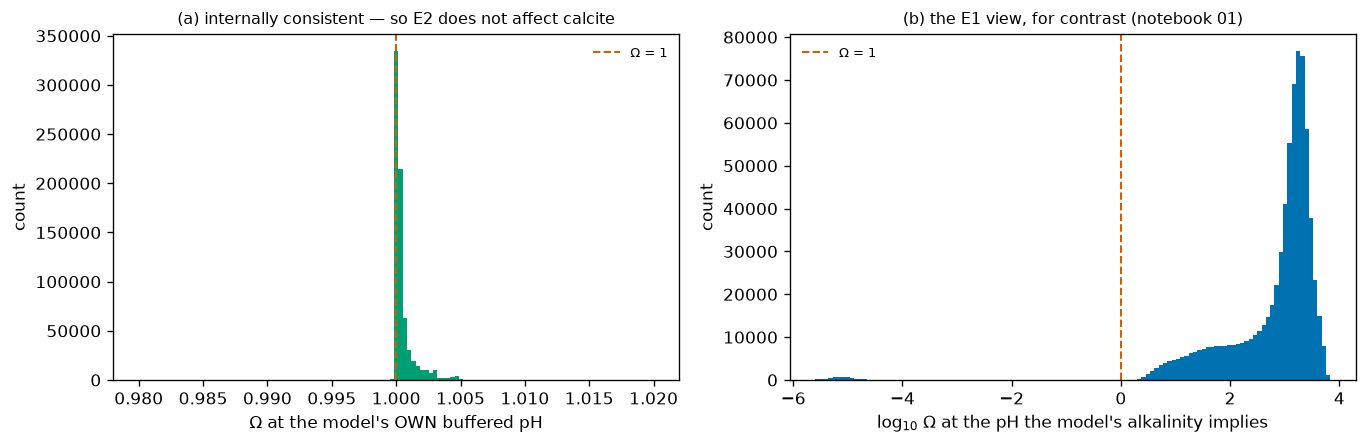

Omega at the model's own pH, where E0 precipitates  (n = 743,710):
  median 1.000187   p1 0.7029   p99 1.0044   max 1.0199
  fraction supersaturated beyond 2%: 0.00000


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))

om_b, om_t = [], []
for (d, c), r in RUNS.items():
    ob = carb.omega(r.Ca_sol, r.pH, r.soil_co2)                       # model's own pH
    ot = carb.omega(r.Ca_sol, carb.alk_to_pH(r.alk_total, r.soil_co2), r.soil_co2)
    g = (r.Ca_precip > 0) & (r.soil_co2 > 0) & np.isfinite(ob) & (ob > 0)
    om_b.append(ob[g]); om_t.append(ot[g])
om_b, om_t = np.concatenate(om_b), np.concatenate(om_t)

ax = axes[0]
ax.hist(om_b, bins=np.linspace(0.98, 1.02, 120), color=OI["green"])
ax.axvline(1.0, color=OI["vermillion"], lw=1.2, ls="--", label="Ω = 1")
ax.set_xlabel("Ω at the model's OWN buffered pH"); ax.set_ylabel("count")
ax.legend(frameon=False, fontsize=8)
ax.set_title("(a) internally consistent — so E2 does not affect calcite", fontsize=9.5)

ax = axes[1]
ax.hist(np.log10(om_t[om_t > 0]), bins=120, color=OI["blue"])
ax.axvline(0, color=OI["vermillion"], lw=1.2, ls="--", label="Ω = 1")
ax.set_xlabel("log$_{10}$ Ω at the pH the model's alkalinity implies")
ax.set_ylabel("count"); ax.legend(frameon=False, fontsize=8)
ax.set_title("(b) the E1 view, for contrast (notebook 01)", fontsize=9.5)
plt.tight_layout(); plt.show()

print(f"Omega at the model's own pH, where E0 precipitates  (n = {om_b.size:,}):")
print(f"  median {np.median(om_b):.6f}   p1 {np.percentile(om_b,1):.4f}   "
      f"p99 {np.percentile(om_b,99):.4f}   max {om_b.max():.4f}")
print(f"  fraction supersaturated beyond 2%: {np.mean(om_b > 1.02):.5f}")

**Median Ω = 1.0000**.

### 2.2 Holding pH holds the kinetics the same

`comp_k.m` depends only on pH and temperature, so E2's dissolution is exact where E1's is an approximation.

### 2.3 The affinity damper only strengthens the bound

Note that `fd15.m:292` damps dissolution by `(1 - C/Ceq)`.

> **E2 is a bound, not a simulation.** Enforcing it in-model needs a sink for the excess cations (exchange,
> secondary minerals, non-carbonate anions).

---
# 3. Carbonate closure cap by site

Flux-weighted at the base node. `over` = exported cation charge ÷ permitted added alkalinity; `f` = multiplier
on E0's cumulative export credit.

In [4]:
hdr = (f"{'site':>12} {'stratum':>16} {'pH':>6} {'pH ctrl':>7} {'pCO2':>6} "
       f"{'model ueq/L':>11} {'cap ueq/L':>9} {'over':>6} {'f':>6}")
print(hdr); print("-" * len(hdr))
rows = []
for (d, c), r in RUNS.items():
    e = E2[(d, c)]
    ph, phc = fw(r, r.pH[BASE]), fw(r, e["pH_ctrl"][BASE])
    co2 = fw(r, r.soil_co2[BASE])
    mod = fw(r, r.cation_alk[BASE]) * 1e6
    capv = fw(r, np.maximum(e["alk_cap"][BASE], 0)) * 1e6
    f = e["f_export_e2"][-1]
    rows.append(dict(d=d, c=c, ph=ph, phc=phc, co2=co2, mod=mod, cap=capv, f=f))
    print(f"{'drv'+str(d)+'-'+str(c):>12} {SITES[d]['stratum']:>16} {ph:6.2f} {phc:7.2f} "
          f"{co2:6.0f} {mod:11.0f} {capv:9.0f} {mod/max(capv,1e-9):6.1f} {f:6.3f}")

ov = np.array([x["mod"] / x["cap"] for x in rows])
print(f"\novercharge factor: {ov.min():.1f}x - {ov.max():.1f}x   (median {np.median(ov):.1f}x)")
print(f"cap never went negative on any run: "
      f"{max(E2[k]['frac_cap_negative'] for k in RUNS):.4f} of live steps")

        site          stratum     pH pH ctrl   pCO2 model ueq/L cap ueq/L   over      f
---------------------------------------------------------------------------------------
      drv6-1 acid + wet + hot   7.33    5.78   3102       23808      1833   13.0  0.077
      drv6-2 acid + wet + hot   7.29    5.77   3102       23057      1578   14.6  0.068
    drv390-1  high efficiency   7.62    6.35   2882       23678      6594    3.6  0.279
    drv390-2  high efficiency   7.51    6.35   2882       19862      3544    5.6  0.179
    drv214-1         very wet   7.39    5.87   3179       23879      2269   10.5  0.095
    drv214-2         very wet   7.38    5.87   3179       24124      2851    8.5  0.118
    drv276-1   dry + alkaline   8.86    8.21   1499       23667     19360    1.2  0.818
    drv276-2   dry + alkaline   8.82    8.21   1501       21365     17027    1.3  0.797
    drv180-1             cold   7.73    6.28   2954       26517      6949    3.8  0.262
    drv180-2             cold   

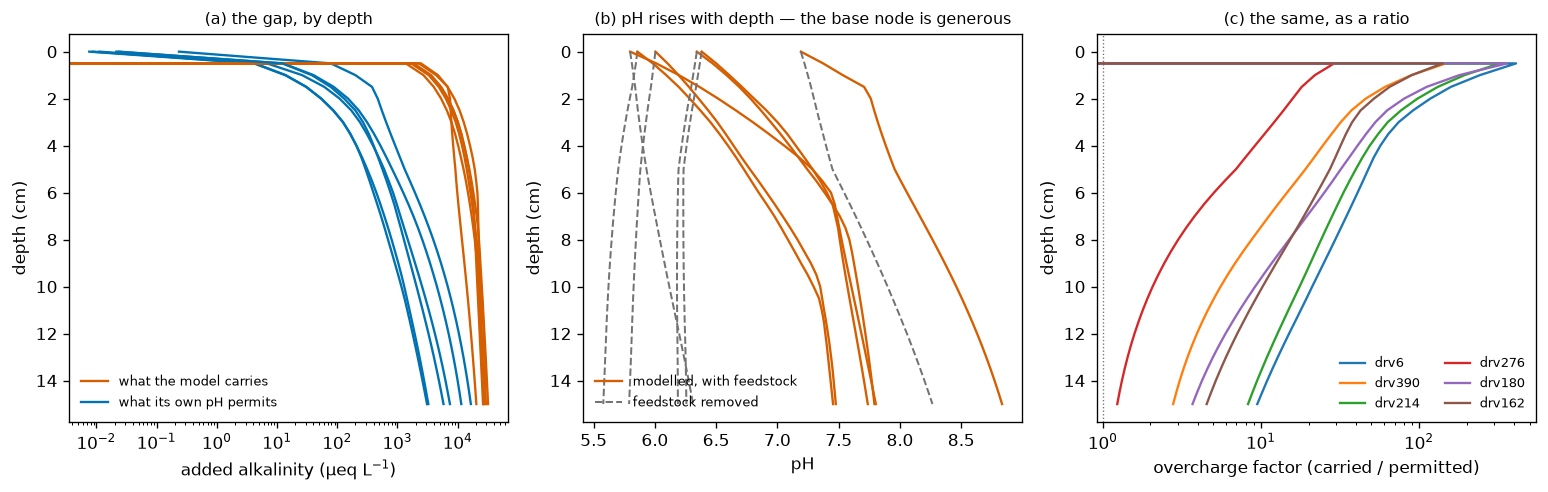

In [5]:
# depth profiles
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))

ax = axes[0]
for d in SITES:
    r, e = RUNS[(d, 1)], E2[(d, 1)]
    g = r.soil_co2 > 0
    add = np.nanmean(np.where(g, r.cation_alk, np.nan), axis=1) * 1e6
    cap = np.nanmean(np.where(g, np.maximum(e["alk_cap"], 0), np.nan), axis=1) * 1e6
    ax.plot(add, r.z * 100, color=OI["vermillion"], lw=1.4)
    ax.plot(cap, r.z * 100, color=OI["blue"], lw=1.4)
ax.set_xscale("log"); ax.invert_yaxis()
ax.set_xlabel("added alkalinity (µeq L$^{-1}$)"); ax.set_ylabel("depth (cm)")
ax.plot([], [], color=OI["vermillion"], lw=1.4, label="what the model carries")
ax.plot([], [], color=OI["blue"], lw=1.4, label="what its own pH permits")
ax.legend(frameon=False, fontsize=8, loc="lower left")
ax.set_title("(a) the gap, by depth", fontsize=9.5)

ax = axes[1]
for d in SITES:
    r, e = RUNS[(d, 1)], E2[(d, 1)]
    g = r.soil_co2 > 0
    ax.plot(np.nanmean(np.where(g, r.pH, np.nan), axis=1), r.z * 100,
            color=OI["vermillion"], lw=1.4)
    ax.plot(np.nanmean(np.where(g, e["pH_ctrl"], np.nan), axis=1), r.z * 100,
            color=OI["grey"], lw=1.2, ls="--")
ax.invert_yaxis(); ax.set_xlabel("pH"); ax.set_ylabel("depth (cm)")
ax.plot([], [], color=OI["vermillion"], lw=1.4, label="modelled, with feedstock")
ax.plot([], [], color=OI["grey"], lw=1.2, ls="--", label="feedstock removed")
ax.legend(frameon=False, fontsize=8, loc="lower left")
ax.set_title("(b) pH rises with depth — the base node is generous", fontsize=9.5)

ax = axes[2]
for d in SITES:
    r, e = RUNS[(d, 1)], E2[(d, 1)]
    g = r.soil_co2 > 0
    ratio = (np.nanmean(np.where(g, r.cation_alk, np.nan), axis=1)
             / np.nanmean(np.where(g, np.maximum(e["alk_cap"], 1e-12), np.nan), axis=1))
    ax.plot(ratio, r.z * 100, lw=1.4, label=f"drv{d}")
ax.set_xscale("log"); ax.invert_yaxis(); ax.axvline(1, color=OI["grey"], lw=.8, ls=":")
ax.set_xlabel("overcharge factor (carried / permitted)"); ax.set_ylabel("depth (cm)")
ax.legend(frameon=False, fontsize=7.5, ncol=2)
ax.set_title("(c) the same, as a ratio", fontsize=9.5)
plt.tight_layout(); plt.show()

In (b), the surface node is pinned at the driver's initial pH (a Dirichlet boundary), and pH
climbs to 7.3–8.9 at 15 cm. 

---
# 4. What it costs

| variant | assumes |
|---|---|
| **export only** | pedogenic calcite earns no credit |
| **+ E0's calcite** | the model's own accounting (`mass_balance.m:233`), untouched by E2 — **the headline** |
| **no baseline** | credit all carbonate alkalinity in the drainage, including what was there anyway |

In [6]:
def mixed(d, key):
    w = mixing.weight(SITES[d]["state"])
    return w * E2[(d, 1)][key][-1] + (1 - w) * E2[(d, 2)][key][-1]

def mixed1(d, key):
    w = mixing.weight(SITES[d]["state"])
    return w * E1[(d, 1)][key][-1] + (1 - w) * E1[(d, 2)][key][-1]

# no-baseline variant: cap on total carbonate alk
def f_nobase(r):
    A = carb.carbonate_alk(r.pH[BASE], r.soil_co2[BASE])
    num = r.export_mol_per_m2(np.maximum(np.where(r.soil_co2[BASE] > 0, A, 0.0), 0.0))[-1]
    den = r.export_mol_per_m2(r.cation_alk[BASE])[-1]
    return min(num / den, 1.0)

print(f"{'site':>12} {'E0':>8} | {'exp only':>9} {'+calcite':>9} {'no base':>8} | {'E1':>8}")
print("-" * 64)
tot = np.zeros(5)
for d in SITES:
    w = mixing.weight(SITES[d]["state"])
    e0   = mixed(d, "cdr_e0_t_ha")
    exp2 = mixed(d, "cdr_export_e2_t_ha")
    e2   = mixed(d, "cdr_e2_t_ha")
    # *_t_ha keys are already t CO2/ha
    nb   = sum(wt * (E2[(d, c)]["cdr_export_e0_t_ha"][-1] * f_nobase(RUNS[(d, c)])
                     + E2[(d, c)]["sic_e0_t_ha"][-1])
               for c, wt in ((1, w), (2, 1 - w)))
    e1   = mixed1(d, "cdr_e1_t_ha")
    tot += [e0, exp2, e2, nb, e1]
    print(f"{'drv'+str(d):>12} {e0:8.1f} | {exp2/e0:9.3f} {e2/e0:9.3f} {nb/e0:8.3f} | {e1/e0:8.3f}")
print("-" * 64)
print(f"{'w. MEAN':>12} {tot[0]/6:8.1f} | {tot[1]/tot[0]:9.3f} {tot[2]/tot[0]:9.3f} "
      f"{tot[3]/tot[0]:8.3f} | {tot[4]/tot[0]:8.3f}")
print("\nThe baseline choice moves the answer by ~1% -- it is not a lever.")

        site       E0 |  exp only  +calcite  no base |       E1
----------------------------------------------------------------
        drv6    269.0 |     0.066     0.188    0.189 |    0.819
      drv390    293.2 |     0.212     0.435    0.439 |    0.909
      drv214    333.9 |     0.084     0.234    0.236 |    0.854
      drv276     90.7 |     0.422     0.896    1.000 |    1.000
      drv180    353.3 |     0.177     0.513    0.515 |    0.949
      drv162    216.8 |     0.121     0.422    0.427 |    0.911
----------------------------------------------------------------
     w. MEAN    259.5 |     0.151     0.392    0.401 |    0.896

The baseline choice moves the answer by ~1% -- it is not a lever.


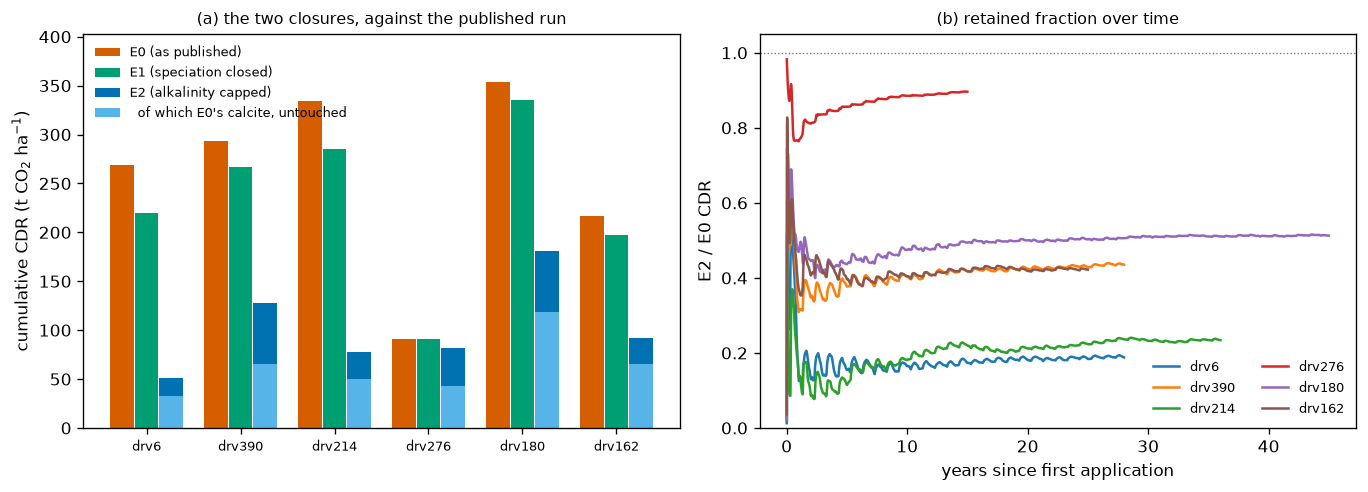

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))

ax = axes[0]
xp = np.arange(len(SITES)); lab = [f"drv{d}" for d in SITES]
e0s  = [mixed(d, "cdr_e0_t_ha") for d in SITES]
e1s  = [mixed1(d, "cdr_e1_t_ha") for d in SITES]
e2s  = [mixed(d, "cdr_e2_t_ha") for d in SITES]
sics = [mixed(d, "sic_e0_t_ha") for d in SITES]     # already t CO2/ha
ax.bar(xp - .26, e0s, .25, color=OI["vermillion"], label="E0 (as published)")
ax.bar(xp,       e1s, .25, color=OI["green"],      label="E1 (speciation closed)")
ax.bar(xp + .26, e2s, .25, color=OI["blue"],       label="E2 (alkalinity capped)")
ax.bar(xp + .26, sics, .25, color=OI["sky"],
       label="  of which E0's calcite, untouched")
ax.set_xticks(xp); ax.set_xticklabels(lab, fontsize=8)
ax.set_ylabel("cumulative CDR (t CO$_2$ ha$^{-1}$)")
ax.legend(frameon=False, fontsize=7.5); ax.margins(y=.14)
ax.set_title("(a) the two closures, against the published run", fontsize=9.5)

ax = axes[1]
for d in SITES:
    w = mixing.weight(SITES[d]["state"])
    r = RUNS[(d, 1)]
    a = w * E2[(d, 1)]["cdr_e2_t_ha"] + (1 - w) * E2[(d, 2)]["cdr_e2_t_ha"]
    b = w * E2[(d, 1)]["cdr_e0_t_ha"] + (1 - w) * E2[(d, 2)]["cdr_e0_t_ha"]
    with np.errstate(invalid="ignore", divide="ignore"):
        ax.plot(r.t, np.where(b > 0, a / b, np.nan), lw=1.5, label=f"drv{d}")
ax.axhline(1, color=OI["grey"], lw=.8, ls=":")
ax.set_xlabel("years since first application"); ax.set_ylabel("E2 / E0 CDR")
ax.set_ylim(0, 1.05); ax.legend(frameon=False, fontsize=8, ncol=2)
ax.set_title("(b) retained fraction over time", fontsize=9.5)
plt.tight_layout(); plt.show()

**drv276 (Oregon)**, dry and alkaline with base-node pH 8.8 and about half its CDR as calcite, retains 0.91.
Virginia (acid, wet, hot, pH 7.3) retains 0.14. **The sites that keep their CDR under E2 are the ones that
were already alkaline**: at the pH the model reports, most of the removal isn't there.

In [8]:
# national totals, if the CONUS point.zarr has E2 fields
import xarray as xr
try:
    P = xr.open_zarr(f"{io.CACHE}/postproc/e0-conus-1gt/point.zarr")
    if "cdr_e2" not in P:
        raise KeyError("cdr_e2")
    a, last = P.area_ha, int(P.time.values[-1])
    g = lambda v: float((P[v].sel(time=last) * a).sum()) / 1e9
    e0, e1, e2 = g("cdr"), g("cdr_e1"), g("cdr_e2")
    print(f"CONUS 1 Gt scenario, cumulative to {last} ({float(a.sum())/1e6:.1f} M ha):")
    print(f"  E0 {e0:6.2f} Gt CO2   (export {g('cdr_export'):.2f} + calcite {g('cdr_precip'):.2f})")
    print(f"  E1 {e1:6.2f} Gt CO2   ({e1/e0:.1%} of E0)")
    print(f"  E2 {e2:6.2f} Gt CO2   ({e2/e0:.1%} of E0)")
except (FileNotFoundError, KeyError, OSError) as err:
    print(f"No E2 fields in the CONUS point.zarr ({type(err).__name__}).")
    print("Re-run postprocess-narrow.ipynb on the e0-conus-1gt batch to fill them in.")
    print("\nFor scale, the E0 batch as it stands is 5.48 Gt to 2070 over 24.4 M ha")
    print("(4.34 export + 1.14 calcite). Note the six sites here are a DELIBERATELY")
    print("STRATIFIED sample, not a representative one -- do not extrapolate the site")
    print("mean to CONUS. The national number needs the full pass.")

No E2 fields in the CONUS point.zarr (FileNotFoundError).
Re-run postprocess-narrow.ipynb on the e0-conus-1gt batch to fill them in.

For scale, the E0 batch as it stands is 5.48 Gt to 2070 over 24.4 M ha
(4.34 export + 1.14 calcite). Note the six sites here are a DELIBERATELY
STRATIFIED sample, not a representative one -- do not extrapolate the site
mean to CONUS. The national number needs the full pass.


---
# 5. Inverted: what would be required

To export its own added alkalinity, the model needs a higher pH or a higher soil pCO₂. Solving for each,
holding the other fixed:

In [9]:
def solve(r, mode):
    """Multiplier on pCO2 ('co2') or offset on pH ('ph') that makes f_export_e2 = 1."""
    co2, ph = r.soil_co2[BASE], r.pH[BASE]
    ctrl_alk = r.alk_ctrl[BASE]
    den = r.export_mol_per_m2(r.cation_alk[BASE])[-1]
    def f(x):
        c = co2 * x if mode == "co2" else co2
        p = ph if mode == "co2" else ph + x
        cap = np.where(co2 > 0, carb.carbonate_alk(p, c)
                       - carb.carbonate_alk(carb.buffered_pH(ctrl_alk, c), c), 0.0)
        return r.export_mol_per_m2(np.maximum(cap, 0.0))[-1] / den - 1.0
    lo, hi = (1.0, 1e3) if mode == "co2" else (0.0, 4.0)
    if f(lo) >= 0:      # already sufficient
        return lo
    return brentq(f, lo, hi)

print(f"{'site':>12} | {'model pH':>8} {'needs pH':>8} {'ΔpH':>6} | "
      f"{'model ppm':>9} {'needs ppm':>9} {'x':>6}")
print("-" * 70)
need = []
for (d, c), r in RUNS.items():
    dph, sc = solve(r, "ph"), solve(r, "co2")
    ph, co2 = fw(r, r.pH[BASE]), fw(r, r.soil_co2[BASE])
    need.append((dph, sc))
    print(f"{'drv'+str(d)+'-'+str(c):>12} | {ph:8.2f} {ph+dph:8.2f} {dph:6.2f} | "
          f"{co2:9.0f} {co2*sc:9.0f} {sc:6.1f}")
dphs = np.array([x[0] for x in need]); scs = np.array([x[1] for x in need])
print(f"\nneeded: +{dphs.min():.2f} to +{dphs.max():.2f} pH units, "
      f"OR {scs.min():.1f}x to {scs.max():.1f}x the soil pCO2")

        site | model pH needs pH    ΔpH | model ppm needs ppm      x
----------------------------------------------------------------------
      drv6-1 |     7.33     8.37   1.05 |      3102     39790   12.8
      drv6-2 |     7.29     8.39   1.10 |      3102     44655   14.4
    drv390-1 |     7.62     8.12   0.50 |      2882     10234    3.6
    drv390-2 |     7.51     8.20   0.69 |      2882     15783    5.5
    drv214-1 |     7.39     8.36   0.96 |      3179     32983   10.4
    drv214-2 |     7.38     8.25   0.87 |      3179     26597    8.4
    drv276-1 |     8.86     8.92   0.07 |      1499      1783    1.2
    drv276-2 |     8.82     8.89   0.07 |      1501      1819    1.2
    drv180-1 |     7.73     8.27   0.55 |      2954     11175    3.8
    drv180-2 |     7.73     8.23   0.50 |      2954     10164    3.4
    drv162-1 |     7.61     8.29   0.68 |      2676     13915    5.2
    drv162-2 |     7.38     8.51   1.12 |      2675     37296   13.9

needed: +0.07 to +1.12 pH units

The model's numbers need drainage at **pH 8.1–8.9**, or **10,000–45,000 ppm CO₂ at 15 cm**, or a mix. This is
more conservative than notebook 01 (~50×), which used **total** alkalinity, including the sigmoid's
fictional 4–19 mM baseline `alk0`. E2 counts only **added** alkalinity, and needs
1.2–14×.

---
# 6. Methods: the annual-mean trap

`alk_cap` is exponential in pH, so it must be accumulated on `fd15`'s 100/yr grid before reducing to annual (Jensen's inequality).

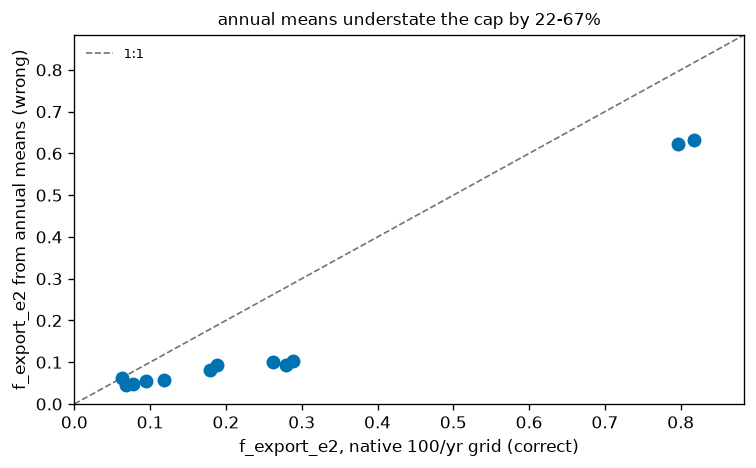

        site   native   annual     bias
      drv6-1   0.0770   0.0489   -36.6%
      drv6-2   0.0685   0.0467   -31.9%
    drv390-1   0.2788   0.0923   -66.9%
    drv390-2   0.1786   0.0821   -54.0%
    drv214-1   0.0951   0.0551   -42.1%
    drv214-2   0.1184   0.0570   -51.8%
    drv276-1   0.8181   0.6310   -22.9%
    drv276-2   0.7970   0.6218   -22.0%
    drv180-1   0.2620   0.0999   -61.9%
    drv180-2   0.2884   0.1035   -64.1%
    drv162-1   0.1876   0.0929   -50.5%
    drv162-2   0.0634   0.0624    -1.5%

bias range: -67% to -2%


In [10]:
def annual(a, n=100):
    a = np.asarray(a)[..., 1:]
    ny = a.shape[-1] // n
    return a[..., :ny * n].reshape(*a.shape[:-1], ny, n).mean(-1)

bias = []
for (d, c), r in RUNS.items():
    native = E2[(d, c)]["f_export_e2"][-1]
    phA, coA, qA = annual(r.pH[BASE]), annual(r.soil_co2[BASE]), annual(r.q)
    catA, alkA = annual(r.cation_alk[BASE]), annual(r.alk_total[BASE])
    capA = np.where(coA > 0, carb.carbonate_alk(phA, coA)
                    - carb.carbonate_alk(carb.buffered_pH(alkA - catA, coA), coA), 0.0)
    ann = np.sum(np.maximum(capA, 0) * qA) / np.sum(catA * qA)
    bias.append((d, c, native, ann))

fig, ax = plt.subplots(figsize=(6.4, 4.0))
nat = np.array([b[2] for b in bias]); an = np.array([b[3] for b in bias])
ax.scatter(nat, an, s=54, color=OI["blue"], zorder=3)
lim = [0, max(nat.max(), an.max()) * 1.08]
ax.plot(lim, lim, color=OI["grey"], lw=1, ls="--", label="1:1")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("f_export_e2, native 100/yr grid (correct)")
ax.set_ylabel("f_export_e2 from annual means (wrong)")
ax.legend(frameon=False, fontsize=8)
ax.set_title("annual means understate the cap by 22-67%", fontsize=10)
plt.tight_layout(); plt.show()

print(f"{'site':>12} {'native':>8} {'annual':>8} {'bias':>8}")
for d, c, n, a in bias:
    print(f"{'drv'+str(d)+'-'+str(c):>12} {n:8.4f} {a:8.4f} {100*(a/n-1):7.1f}%")
print(f"\nbias range: {100*(an/nat-1).min():.0f}% to {100*(an/nat-1).max():.0f}%")


In [ ]:
# ---